### Libraries and Functions

In [2]:
import pandas as pd
import numpy as np
import pickle

from tqdm import tqdm
from sympy import Basic, parse_expr
from joblib import Parallel, delayed
from matplotlib.patches import Patch
from func_timeout import func_timeout, FunctionTimedOut

from symbolic_regression.utils.visualization import plot_results
from symbolic_regression.utils.model_utils import tree_size

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

In [3]:
def get_final_expr(
    dataset_equations: dict[str, list],
    method: str,
    run_idx: int
) -> Basic:
    """
    Extracts the final SymPy expression for a given method and run.

    For the 'RFGPCMI' method, it returns the sum of the final sub-expressions. 
    For all other methods, it returns the single final expression.

    Parameters
    ----------
    dataset_equations : dict[str, list]
        A dictionary containing the equations for a dataset, keyed by method name.
    method : str
        The name of the symbolic regression method (e.g., 'GP', 'RFGPCMI').
    run_idx : int
        The index of the execution run to extract the expression from.

    Returns
    -------
    Basic
        The final SymPy expression.
    """

    if method != "RFGPCMI":
        return dataset_equations [method][run_idx][-1].sympy_format
    
    else:
        return sum(
            sub_expr[-1].sympy_format
            for sub_expr in dataset_equations [method][run_idx]
        ) # type: ignore

def safe_simplify_timeout(
    expr: Basic,
    timeout_seconds: int = 5
):
    """
    Attempts to simplify a SymPy expression within a specified time limit.

    This function uses `func_timeout` to prevent the `simplify` method 
    from running indefinitely. If the simplification takes longer than 
    the given timeout, the original, unsimplified expression is returned.
    Any other exceptions raised during simplification are propagated naturally.

    Parameters
    ----------
    expr : sympy.core.basic.Basic
        The SymPy mathematical expression to be simplified.
    timeout_seconds : int or float, optional
        The maximum number of seconds to allow the simplification process 
        to run. Default is 5.

    Returns
    -------
    sympy.core.basic.Basic
        The simplified SymPy expression if successful and within the time 
        limit; otherwise, the original `expr`.
    """

    try: 
        return func_timeout(timeout_seconds, expr.simplify)
    except FunctionTimedOut:
        return expr

### Data Preprocessing

In [4]:
# Define the true equations as strings for each dataset
true_equations_str = {
    "F1": "-6.67408e-11 * (X1 * X2) / X3**2",
    "F2": "30 * X1 * X3 / ((X1 - 10) * X2**2)",
    "Friedman1": "10 * sin(pi * X1 * X2) + 20 * (X3 - 0.5)**2 + 10 * X4 + 5 * X5",
    "Friedman2": "sqrt( X1**2 + (X2 * X3 - 1 / (X2 * X4))**2 )",
    "Friedman3": "atan((X2 * X3 - 1 / (X2 * X4)) / X1)"
}

In [5]:
# Load real dataset results
with open('data_real.pkl', "rb") as f:
    real = pickle.load(f)['kwargs']

# Load synthetic dataset results
with open('data_synthetic.pkl', "rb") as f:
    synth = pickle.load(f)['kwargs']

results_df = pd.concat([real['df'], synth['df']], axis=1)
features = {**real['features'], **synth['features']}
equations = {**real['equations'], **synth['equations']}
execution_times = {**real['execution_times'], **synth['execution_times']}

# Calculate the number dataframe index runs level
num_runs = results_df.index.get_level_values('run').nunique()

# Reorder MultiIndex columns for consistent plotting
order = {
    'dataset': [
        'F1', 'F2', 'Friedman1', 'Friedman2', 'Friedman3',
        '197_cpu_act', '4544_GOM', '505_tecator', 'CCN', 'CCUN'
    ],
    'method':  ['GPPI', 'GPSHAP', 'GPCMI', 'RFGPCMI', 'GP'],
    'metric':  ['training_losses', 'validation_losses', 'test_losses']
}

for level, cols in order.items():
    results_df = results_df.reindex(columns=cols, level=level)

results_df.tail(3)

dataset                F1                                                \
method               GPPI                                        GPSHAP   
metric    training_losses validation_losses test_losses training_losses   
run epoch                                                                 
99  90           0.000013          0.000015    0.000016        0.001393   
    95           0.000011          0.000020    0.000016        0.001381   
    100          0.000012          0.000019    0.000016        0.001162   

dataset                                                                    \
method                                            GPCMI                     
metric    validation_losses test_losses training_losses validation_losses   
run epoch                                                                   
99  90             0.001232    0.001426        0.000065          0.000120   
    95             0.001246    0.001426        0.000098          0.000077   
    100            0.001298    0.001426        0.000098          0.000078   

dataset                                ...        CCUN                  \
method                        RFGPCMI  ...      GPSHAP           GPCMI   
metric    test_losses training_losses  ... test_losses training_losses   
run epoch                              ...                               
99  90       0.000096        0.001235  ...    0.133757        0.142017   
    95       0.000096        0.001235  ...    0.146277        0.148848   
    100      0.000096        0.000999  ...    0.141008        0.163460   

dataset                                                                    \
method                                          RFGPCMI                     
metric    validation_losses test_losses training_losses validation_losses   
run epoch                                                                   
99  90             0.174450    0.141383        0.139470          0.129479   
    95             0.169583    0.146690        0.141419          0.129395   
    100            0.121239    0.140984        0.137320          0.126764   

dataset                                                              
method                             GP                                
metric    test_losses training_losses validation_losses test_losses  
run epoch                                                            
99  90       0.133781        0.162251          0.135887    0.137342  
    95       0.134067        0.171804          0.182566    0.162457  
    100      0.132307        0.152875          0.168753    0.137342  

[3 rows x 150 columns]

### Predictive Performance

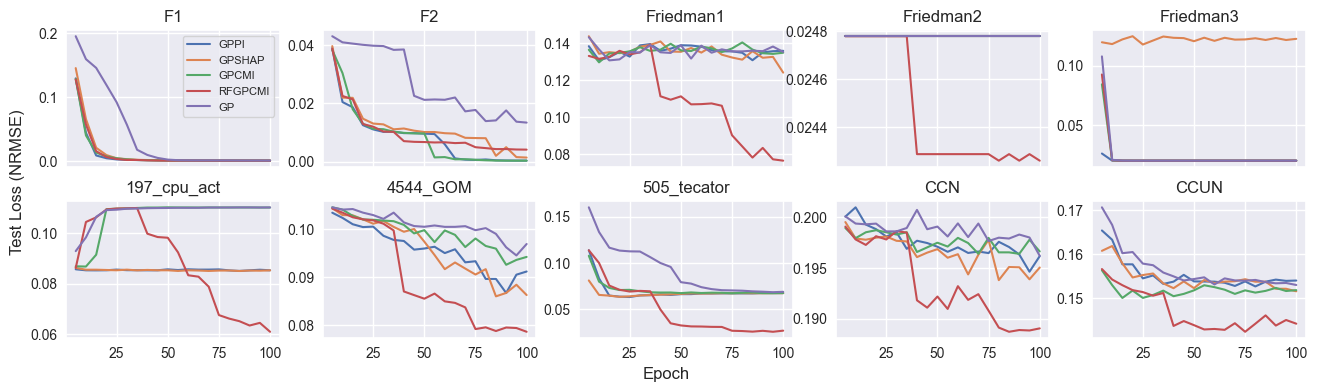

In [6]:
# Plotting test losses for each dataset and method per epoch
fig, axes = plot_results(
    results_df.groupby(level='epoch').median(), 
    nrows=2, 
    ncols=5,
    subplot_kwargs={"sharex": True, "figsize": (16, 4)},
    group_level="dataset",
    value_level="metric",
    value_key="test_losses",
    plotting_function=lambda data, ax: sns.lineplot(data=data, ax=ax, dashes=None)
)

# Set X and Y label for the entire figure
fig.supxlabel("Epoch", x=0.5, y=0.0, size=12)
fig.supylabel("Test Loss (NRMSE)", x=0.09, y=0.5, size=12)

for ax in axes: 
    ax.set_xlabel("") # Hide the x-label
    ax.tick_params(axis='both', which='major', labelsize=10, pad=0)

# Remove legends from individual subplots
for ax in axes[1:]: ax.get_legend().remove()

# Extract and resize the legend on the first subplot
handles, labels = axes[0].get_legend_handles_labels()
axes[0].legend(handles, labels, fontsize=8) 

fig.subplots_adjust(wspace=0.2, hspace=0.25) 

plt.show()

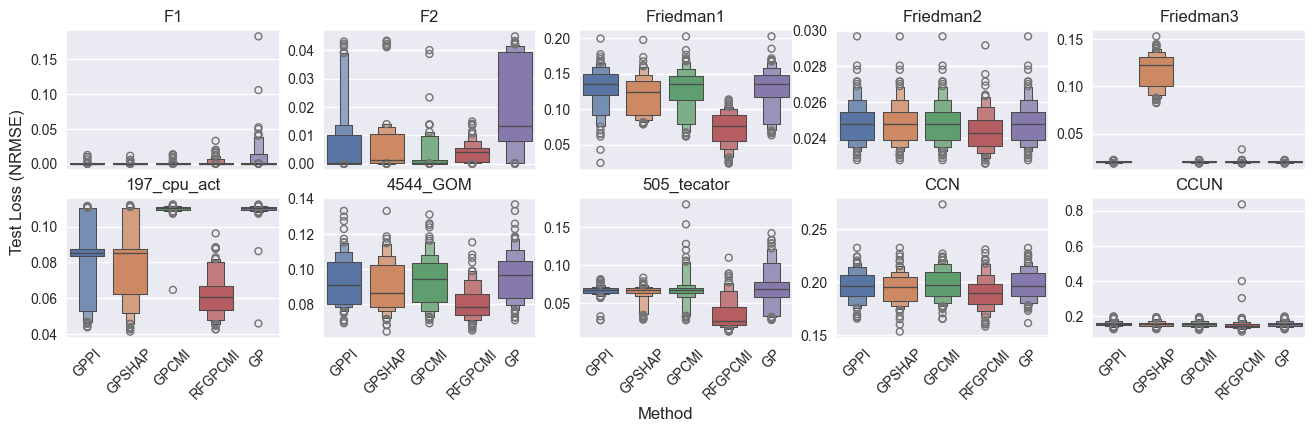

In [7]:
# Plotting test losses for each dataset and method at the last epoch
fig, axes = plot_results(
    results_df.groupby(level='run').last(), 
    nrows=2, 
    ncols=5, 
    subplot_kwargs={"sharex": True, "figsize": (16, 4)},
    group_level="dataset",
    value_level="metric", 
    value_key="test_losses",
    plotting_function=lambda data, ax: sns.boxenplot(data=data, ax=ax)
)

# Set X and Y label for the entire figure
fig.supxlabel("Method", x=0.5, y=-0.1, size=12)
fig.supylabel("Test Loss (NRMSE)", x=0.09, y=0.5, size=12)

for ax in axes: 
    ax.set_xlabel("") # Hide the x-label
    ax.tick_params(axis='both', which='major', labelsize=10, pad=0)
    ax.tick_params(axis='x', which='major', labelrotation=45)

# Create a custom legend with the same colors as the boxenplots
colors = sns.color_palette(n_colors=len(order['method']))
handles = [Patch(facecolor=c) for c in colors]
labels = order['method'].copy()

plt.show()

In [8]:
# Calculate median test losses for each method and dataset at the last epoch
median_loss = results_df.groupby(level='run').last().median()
gp_median_loss = median_loss[:, "GP", :]

# Extract the list of methods excluding "GP" for comparison
methods = results_df.columns.levels[1].to_list()
methods.remove("GP")

# Extract the median losses for the competitor methods
competitor_median_loss = median_loss.loc[:, methods, :]

# Calculate relative improvement of GP over competitors for each dataset and metric
relative_improvement = (gp_median_loss - competitor_median_loss) * 100 / gp_median_loss
relative_improvement_df = relative_improvement.to_frame().T

# Reorder the relative improvement DataFrame to match the desired column order for plotting
relative_improvement_df = relative_improvement_df.swaplevel('metric', 'method', axis=1)
relative_improvement_df = relative_improvement_df.reindex(columns=order['dataset'], level='dataset')
relative_improvement_df = relative_improvement_df.reindex(columns=methods, level='method')
relative_improvement_df = relative_improvement_df.reindex(columns=order['metric'], level='metric')
relative_improvement_df

dataset              F1                                                \
method             GPPI                                        GPSHAP   
metric  training_losses validation_losses test_losses training_losses   
0             67.902827         66.427378   56.363705        50.39442   

dataset                                                                  \
method                                          GPCMI                     
metric  validation_losses test_losses training_losses validation_losses   
0               48.221107   48.117945       60.139743         63.604261   

dataset                              ...        CCUN                  \
method                      RFGPCMI  ...        GPPI          GPSHAP   
metric  test_losses training_losses  ... test_losses training_losses   
0         53.306855       99.787335  ...   -0.662397       -1.526991   

dataset                                                                  \
method                                          GPCMI                     
metric  validation_losses test_losses training_losses validation_losses   
0                2.071164    0.935366        1.095375          1.998868   

dataset                                                            
method                      RFGPCMI                                
metric  test_losses training_losses validation_losses test_losses  
0           0.76335        9.284465         12.132357    5.748787  

[1 rows x 120 columns]

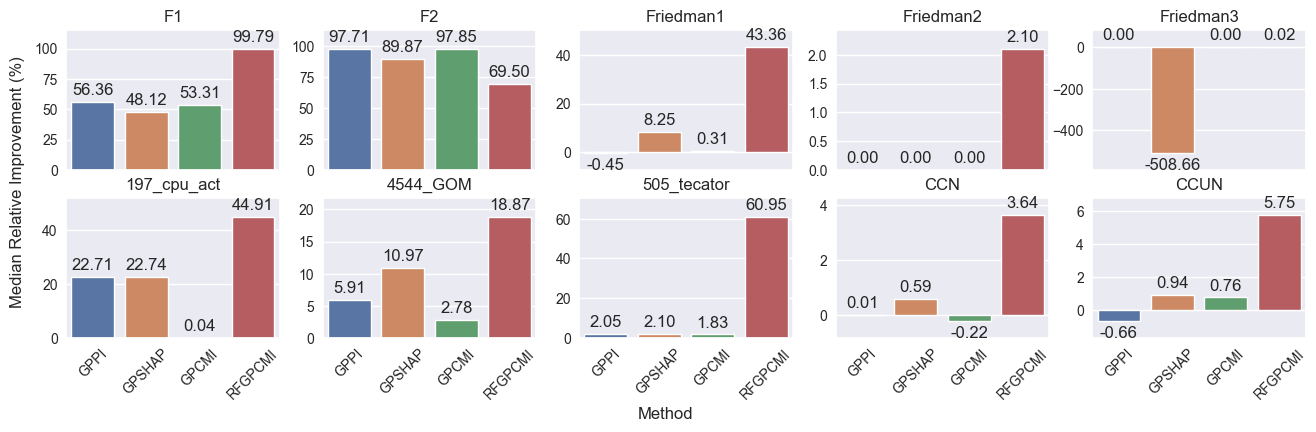

In [9]:
# Plotting relative performance of each method compared to GP for each dataset
fig, axes = plot_results(
    relative_improvement_df, 
    nrows=2, 
    ncols=5, 
    subplot_kwargs={"sharex": True, "figsize": (16, 4)},
    group_level="dataset",
    value_level="metric", 
    value_key="test_losses",
    plotting_function=lambda data, ax: sns.barplot(data=data, ax=ax),
)

# Set X and Y label for the entire figure
fig.supxlabel("Method", x=0.5, y=-0.1, size=12)
fig.supylabel("Median Relative Improvement (%)", x=0.09, y=0.5, size=12)

# Create a custom legend with the same colors as the boxenplots
colors = sns.color_palette(n_colors=len(order['method']))
handles = [Patch(facecolor=c) for c in colors]
labels = order['method'].copy()

# plt.show()

# Add value labels on top of each bar and adjust y-axis limits for better visibility
for ax in axes:
    base_padding = 3
    margin_ratio = 0.1

    bottom, top = ax.get_ylim()
    y_padding = margin_ratio * (top - bottom)

    new_top = top + (y_padding if top else 0)
    new_bottom = bottom - (y_padding if bottom else 0)
    ax.set_ylim(new_bottom, new_top)

    for container in ax.containers:
        v = container.datavalues[0]
        adjusted_padding = base_padding if (v != 0) or (top > 0) else -(11 + base_padding)
        ax.bar_label(container, fmt='%.2f', padding=adjusted_padding)

    ax.set_xlabel("") # Hide the x-label
    ax.tick_params(axis='both', which='major', labelsize=10, pad=0)
    ax.tick_params(axis='x', which='major', labelrotation=45)

plt.show()

### Model Complexity

In [10]:
# Parse the true equations into SymPy expressions
true_equations_expr = {
    name: parse_expr(eq_str)
    for name, eq_str in true_equations_str.items()
}

# Calculate true tree sizes for each dataset using the true equations
true_sizes = {
    dataset: tree_size(expr)
    for dataset, expr in true_equations_expr.items()
}

In [11]:
# Calculate tree sizes for each run, method, and dataset in parallel using joblib
tree_sizes = {}
for ds in order['dataset']:
    tree_sizes[ds] = {}

    for m in order['method']:
        tree_sizes[ds][m] = Parallel(n_jobs=1)(
            delayed(tree_size)(
                safe_simplify_timeout(get_final_expr(equations[ds], m, run), 10)
            ) for run in tqdm(range(num_runs), desc=f"Calculating tree sizes for {ds} - {m}")  
        )

Calculating tree sizes for CCUN - GP: 100%|██████████| 100/100 [00:01<00:00, 79.08it/s]


In [12]:
# Create a DataFrame to store tree sizes with MultiIndex columns for dataset and method
tree_sizes_column_order = pd.MultiIndex.from_product([order['dataset'], order['method']], names=['dataset', 'method'])

tree_sizes_df = pd.concat(
    {ds: pd.DataFrame(tree_sizes[ds]) for ds in order['dataset']},
    axis=1,
).reindex(columns=tree_sizes_column_order)
tree_sizes_df.index.name = "run"
tree_sizes_df.tail(3)

dataset   F1                           F2                           ...  CCN  \
method  GPPI GPSHAP GPCMI RFGPCMI GP GPPI GPSHAP GPCMI RFGPCMI  GP  ... GPPI   
run                                                                 ...        
97         7      7     7      23  7   19      9    12      16   7  ...    2   
98         7      7     7      21  7    9      8    12      16   4  ...    2   
99         7      7     7      64  7   13      9    12      16  15  ...    2   

dataset                         CCUN                          
method  GPSHAP GPCMI RFGPCMI GP GPPI GPSHAP GPCMI RFGPCMI GP  
run                                                           
97           2     2      13  2    3      3     6      34  3  
98           2     5      18  2    3      6     5      17  3  
99           5     6      30  2    5      3     3      11  5  

[3 rows x 50 columns]

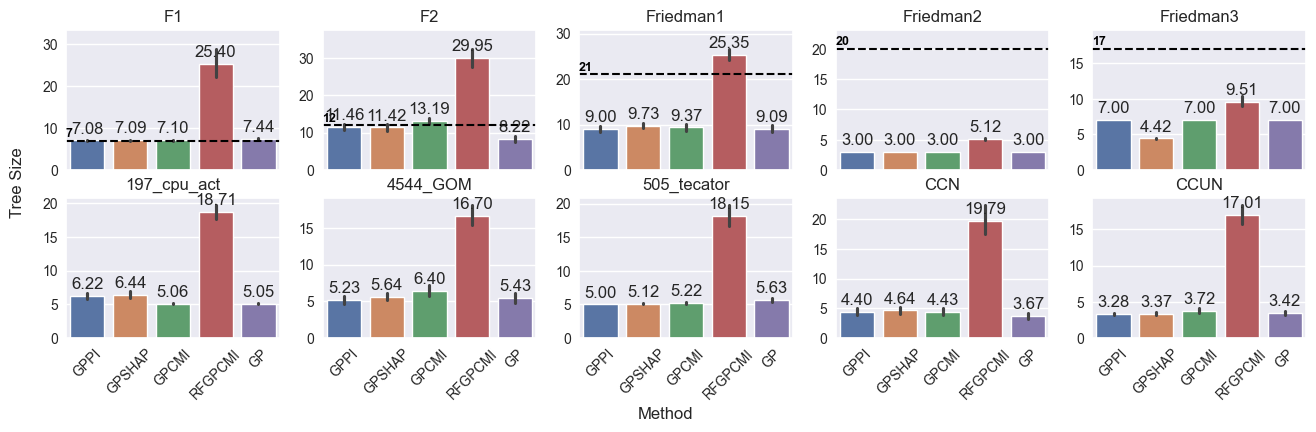

In [13]:
# Plotting tree sizes for each dataset and method at the last epoch
fig, axes = plot_results(
    tree_sizes_df, 
    nrows=2, 
    ncols=5, 
    subplot_kwargs={"sharex": True, "figsize": (16, 4)},
    group_level="dataset",
    value_level=None, 
    value_key=None,
    plotting_function=lambda data, ax: sns.barplot(data=data, ax=ax),
)

# Set X and Y label for the entire figure
fig.supxlabel("Method", x=0.5, y=-0.1, size=12)
fig.supylabel("Tree Size", x=0.09, y=0.5, size=12)

for ax in axes:
    base_padding = 3
    margin_ratio = 0.1
    text_offset_ratio = 0.03
    fontsize = 9

    dataset_name = ax.get_title()
    if dataset_name in true_sizes:
        true_value = true_sizes[dataset_name]

        ax.axhline(
            y=true_value, 
            color='black', 
            linestyle='--', 
            linewidth=1.5,
            label='True Equation Size'
        )

        bottom, top = ax.get_ylim()
        y_padding = margin_ratio * (top - bottom)   

        new_top = top + (y_padding if top else 0)
        new_bottom = bottom - (y_padding if bottom else 0)
        ax.set_ylim(new_bottom, new_top)

        ax.text(
            ax.get_xlim()[0], 
            true_value + text_offset_ratio * (top - bottom),
            f'{true_value}', 
            color='black',
            fontweight='bold',
            fontsize=fontsize,
        ) 

    for container in ax.containers:
        v = container.datavalues[0]
        adjusted_padding = base_padding if (v != 0) or (top > 0) else -(11 + base_padding)
        ax.bar_label(container, fmt='%.2f', padding=adjusted_padding)

    ax.set_xlabel("") # Hide the x-label
    ax.tick_params(axis='both', which='major', labelsize=10, pad=0)
    ax.tick_params(axis='x', which='major', labelrotation=45)

plt.show()

### Feature Selection Analysis

In [14]:
# Total initial number of features for each real dataset
total_features_per_dataset = {ds: len(features[ds]['GP'][0]) for ds in features}    

# Extract the list of methods excluding "GP" for comparison
methods = results_df.columns.levels[1].to_list()
methods.remove("GP")

In [15]:
# Calculate feature retention rate (percentage) for each method and dataset
retention_rates = {}

for dataset_name in order['dataset']:
    retention_rates[dataset_name] = {}
    total_features = total_features_per_dataset[dataset_name]

    for method_name in methods:
        retention_rates[dataset_name][method_name] = np.empty(num_runs)
        features_selected = features[dataset_name][method_name]

        for run in range(num_runs): 
            if method_name == "RFGPCMI":
                selected_features = set()

                for feature_list in features_selected[run]:
                    selected_features.update(feature_list)
                    
            else:
                selected_features = set(features_selected[run])

            # Percentage of original features retained
            retention_rates[dataset_name][method_name][run] = (len(selected_features) / total_features) * 100

In [16]:
# Create a DataFrame to store retention rates with MultiIndex columns for dataset and method
retention_column_order = pd.MultiIndex.from_product(
    [order['dataset'], methods], names=['dataset', 'method']
)

retention_rate_df = pd.concat(
    {
        ds: pd.DataFrame(retention_rates[ds])
        for ds in order['dataset']
    },
    axis=1,
).reindex(columns=retention_column_order)
retention_rate_df.index.name = "run"
retention_rate_df.tail(3)

dataset        F1                                        F2             \
method       GPPI     GPSHAP     GPCMI    RFGPCMI      GPPI     GPSHAP   
run                                                                      
97       5.660377  11.320755  5.660377   5.660377  5.660377  11.320755   
98       5.660377  11.320755  7.547170   5.660377  5.660377  11.320755   
99       5.660377  11.320755  9.433962  11.320755  5.660377  11.320755   

dataset                     Friedman1         ... 505_tecator             \
method      GPCMI   RFGPCMI      GPPI GPSHAP  ...       GPCMI    RFGPCMI   
run                                           ...                          
97       5.660377  5.660377      50.0   30.0  ...   91.935484  94.354839   
98       5.660377  9.433962      60.0   30.0  ...   92.741935  94.354839   
99       5.660377  5.660377      50.0   30.0  ...    3.225806   6.451613   

dataset       CCN                                     CCUN            \
method       GPPI    GPSHAP     GPCMI    RFGPCMI      GPPI    GPSHAP   
run                                                                    
97       9.016393  5.737705  7.377049  15.573770  2.419355  5.645161   
98       5.737705  5.737705  8.196721   9.016393  3.225806  5.645161   
99       9.836066  5.737705  9.016393  15.573770  6.451613  5.645161   

dataset                       
method      GPCMI    RFGPCMI  
run                           
97       5.645161   9.677419  
98       1.612903  11.290323  
99       4.838710   6.451613  

[3 rows x 40 columns]

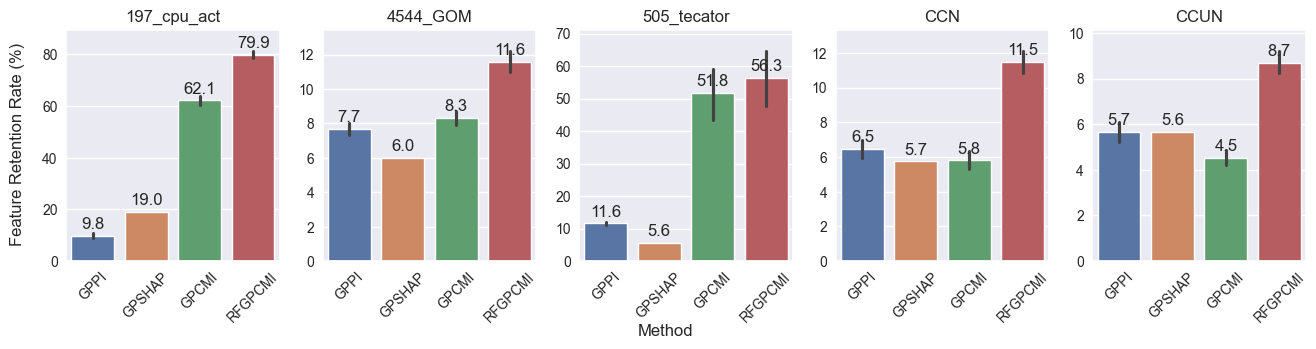

In [17]:
# Plotting feature retention rates for each dataset and method
fig, axes = plot_results(
    retention_rate_df[['197_cpu_act', '4544_GOM', '505_tecator', 'CCN', 'CCUN']], 
    nrows=1, 
    ncols=5, 
    subplot_kwargs={"sharex": True, "figsize": (16, 3)},
    group_level="dataset",
    value_level=None, 
    value_key=None,
    plotting_function=lambda data, ax: sns.barplot(data=data, ax=ax),
)

# Set X and Y label for the entire figure
fig.supxlabel("Method", x=0.5, y=-0.15, size=12)
fig.supylabel("Feature Retention Rate (%)", x=0.09, y=0.5, size=12)

# Add value labels on top of each bar and adjust y-axis limits for better visibility
for ax in axes:
    base_padding = 3
    margin_ratio = 0.05

    # ax.axhline(y=100, color='black', linestyle='--', linewidth=1)

    bottom, top = ax.get_ylim()
    y_padding = margin_ratio * (top - bottom)

    new_top = top + (y_padding if top else 0)
    new_bottom = bottom - (y_padding if bottom else 0)
    ax.set_ylim(new_bottom, new_top)

    for container in ax.containers:
        v = container.datavalues[0]
        adjusted_padding = base_padding if (v != 0) or (top > 0) else -(11 + base_padding)
        ax.bar_label(container, fmt='%.1f', padding=adjusted_padding)

    ax.set_xlabel("") # Hide the x-label
    ax.tick_params(axis='both', which='major', labelsize=10, pad=0)
    ax.tick_params(axis='x', which='major', labelrotation=45)

plt.show()

### Feature Selection Analysis 2

In [18]:
# Extract the true features used in each dataset's true equation
true_features_per_dataset = {
    dataset_name: {
        str(symbol) for symbol in equation.free_symbols
    } for dataset_name, equation in true_equations_expr.items()
}

In [19]:
# Calculate selection rates (TPR and FPR) for each method and dataset
selection_rates = {}

for dataset_name in ['F1', 'F2', 'Friedman1', 'Friedman2', 'Friedman3']:
    selection_rates[dataset_name] = {}

    for method_name in order['method']:
        selection_rates[dataset_name][method_name] = {
            "tpr": np.empty(num_runs),
            "fdr": np.empty(num_runs)
        }
        features_selected = features[dataset_name][method_name]

        for run in range(num_runs): 
            if method_name == "RFGPCMI":
                selected_features = set()

                for feature_list in features_selected[run]:
                    selected_features.update(feature_list)

            else:
                selected_features = set(features_selected[run])

            true_features = true_features_per_dataset[dataset_name]
            correctly_selected = selected_features & true_features
            falsely_selected = selected_features - true_features

            selection_rates[dataset_name][method_name]["tpr"][run] = len(correctly_selected) / len(true_features)
            selection_rates[dataset_name][method_name]["fdr"][run] = len(falsely_selected) / len(selected_features)

In [20]:
# Create a DataFrame to store selection rates with MultiIndex columns for dataset, method, and rate type (TPR/FDR)
selection_rate_types = ['tpr', 'fdr'] 
selection_rate_column_order = pd.MultiIndex.from_product(
    [['F1', 'F2', 'Friedman1', 'Friedman2', 'Friedman3'], order['method'], selection_rate_types], names=['dataset', 'method', 'rate_type']
)

selection_rate_df = pd.concat(
    {
        (ds, method): pd.DataFrame(selection_rates[ds][method])
        for ds in ['F1', 'F2', 'Friedman1', 'Friedman2', 'Friedman3']
        for method in order['method']
    },
    axis=1,
).reindex(columns=selection_rate_column_order)
selection_rate_df.index.name = "run"
selection_rate_df.tail(3)

dataset     F1                                                           ...  \
method    GPPI      GPSHAP      GPCMI       RFGPCMI        GP            ...   
rate_type  tpr  fdr    tpr  fdr   tpr   fdr     tpr  fdr  tpr       fdr  ...   
run                                                                      ...   
97         1.0  0.0    1.0  0.5   1.0  0.00     1.0  0.0  1.0  0.943396  ...   
98         1.0  0.0    1.0  0.5   1.0  0.25     1.0  0.0  1.0  0.943396  ...   
99         1.0  0.0    1.0  0.5   1.0  0.40     1.0  0.5  1.0  0.943396  ...   

dataset   Friedman3                                                     
method         GPPI      GPSHAP      GPCMI      RFGPCMI        GP       
rate_type       tpr  fdr    tpr  fdr   tpr  fdr     tpr  fdr  tpr  fdr  
run                                                                     
97             0.75  0.0    0.5  0.0  0.75  0.0    0.75  0.0  1.0  0.0  
98             0.75  0.0    0.5  0.0  0.75  0.0    0.75  0.0  1.0  0.0  
99             0.75  0.0    0.5  0.0  0.75  0.0    0.75  0.0  1.0  0.0  

[3 rows x 50 columns]

In [21]:
tpr = selection_rate_df.xs(key='tpr', level='rate_type', axis=1)
fdr = selection_rate_df.xs(key='fdr', level='rate_type', axis=1)
fdr.columns = pd.MultiIndex.from_tuples([(idx[0]+'_', idx[1]) for idx in fdr.columns], names=['dataset', 'method'])
tpr_fdr = pd.concat([tpr, fdr], axis=1)
tpr_fdr

dataset   F1                             F2                            ...  \
method  GPPI GPSHAP GPCMI RFGPCMI   GP GPPI GPSHAP GPCMI RFGPCMI   GP  ...   
run                                                                    ...   
0        1.0    1.0   1.0     1.0  1.0  1.0    1.0   1.0     1.0  1.0  ...   
1        1.0    1.0   1.0     1.0  1.0  1.0    1.0   1.0     1.0  1.0  ...   
2        1.0    1.0   1.0     1.0  1.0  1.0    1.0   1.0     1.0  1.0  ...   
3        1.0    1.0   1.0     1.0  1.0  1.0    1.0   1.0     1.0  1.0  ...   
4        1.0    1.0   1.0     1.0  1.0  1.0    1.0   1.0     1.0  1.0  ...   
..       ...    ...   ...     ...  ...  ...    ...   ...     ...  ...  ...   
95       1.0    1.0   1.0     1.0  1.0  1.0    1.0   1.0     1.0  1.0  ...   
96       1.0    1.0   1.0     1.0  1.0  1.0    1.0   1.0     1.0  1.0  ...   
97       1.0    1.0   1.0     1.0  1.0  1.0    1.0   1.0     1.0  1.0  ...   
98       1.0    1.0   1.0     1.0  1.0  1.0    1.0   1.0     1.0  1.0  ...   
99       1.0    1.0   1.0     1.0  1.0  1.0    1.0   1.0     1.0  1.0  ...   

dataset Friedman2_                           Friedman3_                       \
method        GPPI GPSHAP GPCMI RFGPCMI   GP       GPPI GPSHAP GPCMI RFGPCMI   
run                                                                            
0              0.0    0.0   0.0     0.0  0.0        0.0    0.0   0.0     0.0   
1              0.0    0.0   0.0     0.0  0.0        0.0    0.0   0.0     0.0   
2              0.0    0.0   0.0     0.0  0.0        0.0    0.0   0.0     0.0   
3              0.0    0.0   0.0     0.0  0.0        0.0    0.0   0.0     0.0   
4              0.0    0.0   0.0     0.0  0.0        0.0    0.0   0.0     0.0   
..             ...    ...   ...     ...  ...        ...    ...   ...     ...   
95             0.0    0.0   0.0     0.0  0.0        0.0    0.0   0.0     0.0   
96             0.0    0.0   0.0     0.0  0.0        0.0    0.0   0.0     0.0   
97             0.0    0.0   0.0     0.0  0.0        0.0    0.0   0.0     0.0   
98             0.0    0.0   0.0     0.0  0.0        0.0    0.0   0.0     0.0   
99             0.0    0.0   0.0     0.0  0.0        0.0    0.0   0.0     0.0   

dataset       
method    GP  
run           
0        0.0  
1        0.0  
2        0.0  
3        0.0  
4        0.0  
..       ...  
95       0.0  
96       0.0  
97       0.0  
98       0.0  
99       0.0  

[100 rows x 50 columns]

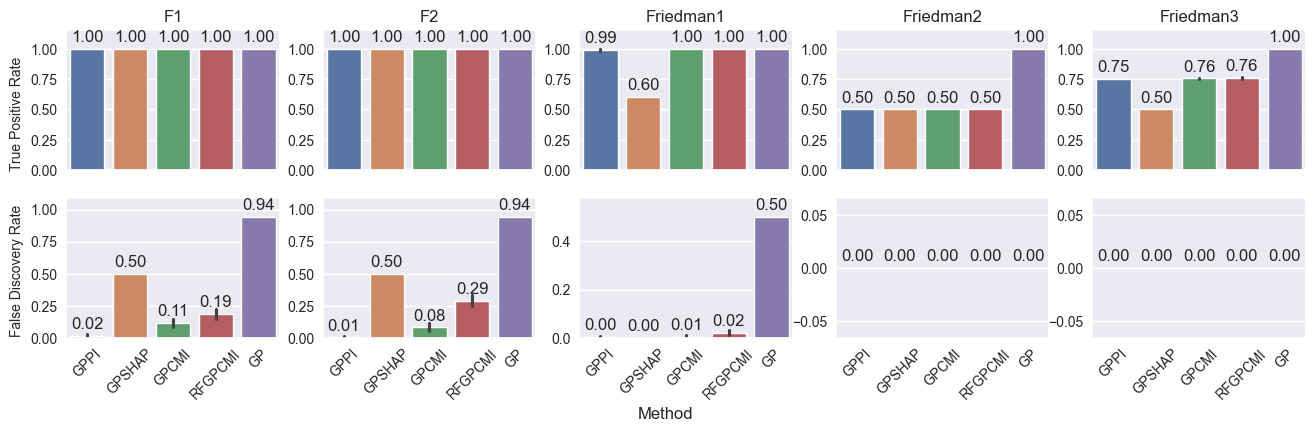

In [22]:
# Plotting true positive rates for each dataset and method at the last epoch
fig, axes = plot_results(
    tpr_fdr, 
    nrows=2, 
    ncols=5, 
    subplot_kwargs={"sharex": True, "figsize": (16, 4)},
    group_level="dataset",
    value_level=None, 
    value_key=None,
    plotting_function=lambda data, ax: sns.barplot(data=data, ax=ax),
)

# Set X and Y label for the entire figure
fig.supxlabel("Method", x=0.5, y=-0.1, size=12)
fig.supylabel("True Positive Rate", x=0.09, y=0.67, size=10)
plt.text(0.09, 0.12, "False Discovery Rate", rotation=90, transform=fig.transFigure, size=10)
# fig.supylabel("False Discovery Rate", x=0.09, y=0.1, size=10)

# Add value labels on top of each bar and adjust y-axis limits for better visibility
for ax in axes:
    base_padding = 3
    margin_ratio = 0.1

    bottom, top = ax.get_ylim()
    y_padding = margin_ratio * (top - bottom)

    new_top = top + (y_padding if top else 0)
    new_bottom = bottom - (y_padding if bottom else 0)
    ax.set_ylim(new_bottom, new_top)

    for container in ax.containers:
        v = container.datavalues[0]
        adjusted_padding = base_padding if (v != 0) or (top > 0) else -(11 + base_padding)
        ax.bar_label(container, fmt='%.2f', padding=adjusted_padding)

    ax.set_xlabel("") # Hide the x-label
    ax.tick_params(axis='both', which='major', labelsize=10, pad=0)
    ax.tick_params(axis='x', which='major', labelrotation=45)

for ax in axes[5:]:
    ax.set_title("")

plt.show()

### Computational Efficiency

In [23]:
# Create a DataFrame to store execution times with MultiIndex columns for dataset and method
time_column_order = pd.MultiIndex.from_product(
    [order['dataset'], order['method']], names=['dataset', "method"]
)

execution_time_df = pd.concat({ds: pd.DataFrame(execution_times[ds]) for ds in order['dataset']},
    axis=1,
).reindex(columns=time_column_order)
execution_time_df.index.name = "run"
execution_time_df.tail(3)

dataset          F1                                                       F2  \
method         GPPI      GPSHAP      GPCMI    RFGPCMI         GP        GPPI   
run                                                                            
97       678.777365  690.168520  35.963639  54.710922  37.186884  503.791579   
98       325.560931  432.049777  35.529003  57.216654  41.019608  548.239259   
99       681.988584  727.554824  47.669574  56.724390  39.798209  470.084329   

dataset                                                 ...         CCN  \
method        GPSHAP      GPCMI     RFGPCMI         GP  ...        GPPI   
run                                                     ...               
97        936.449190  60.127984   93.643908  40.962508  ...  564.998186   
98       1193.430691  71.820931  107.878357  44.217799  ...  545.597015   
99       1197.210956  67.532704   96.977592  44.414566  ...  528.371934   

dataset                                                       CCUN  \
method       GPSHAP       GPCMI     RFGPCMI         GP        GPPI   
run                                                                  
97       533.189034   91.477747  103.750733  74.521352  738.301146   
98       590.285738   97.832454   91.367429  70.146157  768.466217   
99       589.226756  102.298260  110.174205  73.736871  786.458495   

dataset                                                  
method       GPSHAP       GPCMI     RFGPCMI          GP  
run                                                      
97       786.917845  107.615788  116.398739   98.138171  
98       796.702661  101.793739  123.709903   94.702348  
99       790.859068  109.773094  111.918825  101.232751  

[3 rows x 50 columns]

In [24]:
# Calculate median relative time for each method and dataset
median_exec_time = execution_time_df.median()
baseline_exec_time = median_exec_time[:, "GP"]

relative_time = median_exec_time / baseline_exec_time
relative_time_df = relative_time.to_frame().T

relative_time_df = relative_time_df.reindex(columns=order['dataset'], level='dataset')
relative_time_df = relative_time_df.reindex(columns=order['method'], level='method')
for d in order['dataset']:
    print()
    print(d)
    print('--------')
    for m in order['method']:
        print(f"{m:>10}: {relative_time_df[d][m].values[0]:.1f}")


F1
--------
      GPPI: 17.0
    GPSHAP: 14.9
     GPCMI: 1.0
   RFGPCMI: 1.5
        GP: 1.0

F2
--------
      GPPI: 11.8
    GPSHAP: 26.0
     GPCMI: 1.7
   RFGPCMI: 2.4
        GP: 1.0

Friedman1
--------
      GPPI: 9.0
    GPSHAP: 10.7
     GPCMI: 1.1
   RFGPCMI: 1.3
        GP: 1.0

Friedman2
--------
      GPPI: 8.6
    GPSHAP: 8.7
     GPCMI: 1.0
   RFGPCMI: 0.4
        GP: 1.0

Friedman3
--------
      GPPI: 8.6
    GPSHAP: 9.6
     GPCMI: 1.2
   RFGPCMI: 0.4
        GP: 1.0

197_cpu_act
--------
      GPPI: 13.5
    GPSHAP: 17.9
     GPCMI: 5.4
   RFGPCMI: 14.6
        GP: 1.0

4544_GOM
--------
      GPPI: 11.3
    GPSHAP: 12.9
     GPCMI: 1.3
   RFGPCMI: 1.5
        GP: 1.0

505_tecator
--------
      GPPI: 9.0
    GPSHAP: 9.9
     GPCMI: 2.6
   RFGPCMI: 2.8
        GP: 1.0

CCN
--------
      GPPI: 7.3
    GPSHAP: 8.0
     GPCMI: 1.3
   RFGPCMI: 1.4
        GP: 1.0

CCUN
--------
      GPPI: 7.9
    GPSHAP: 8.1
     GPCMI: 1.1
   RFGPCMI: 1.2
        GP: 1.0


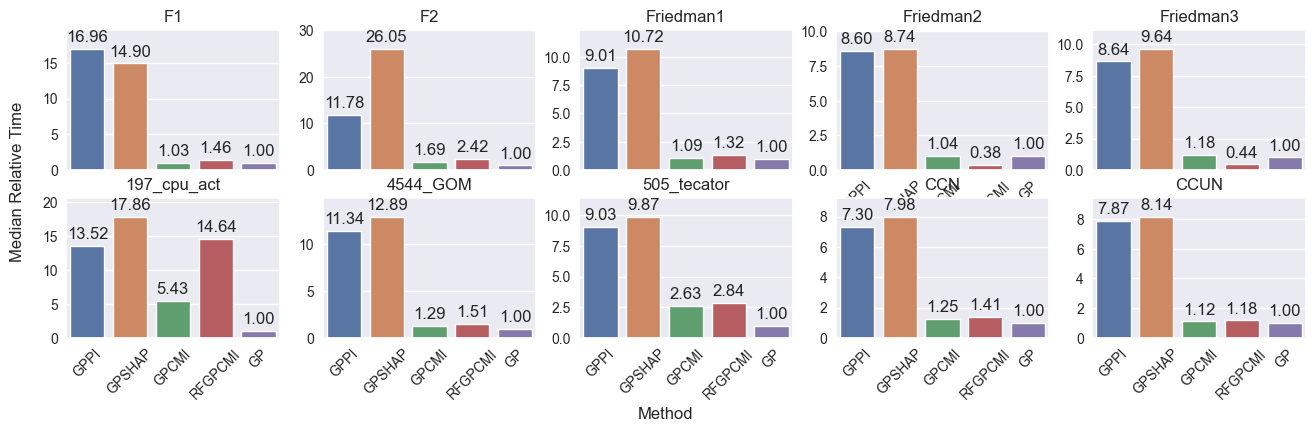

In [25]:
# Plotting relative time of each method compared to GP for each dataset
fig, axes = plot_results(
    relative_time_df, 
    nrows=2, 
    ncols=5, 
    subplot_kwargs={"sharex": True, "figsize": (16, 4)},
    group_level="dataset",
    value_level=None, 
    value_key=None,
    plotting_function=lambda data, ax: sns.barplot(data=data, ax=ax),
)

# Set X and Y label for the entire figure
fig.supxlabel("Method", x=0.5, y=-0.1, size=12)
fig.supylabel("Median Relative Time", x=0.09, y=0.5, size=12)


axes[3].tick_params(axis='x', labelbottom=True) # Restore x-tick labels

# Add value labels on top of each bar and adjust y-axis limits for better visibility
for ax in axes:
    base_padding = 3
    margin_ratio = 0.1

    bottom, top = ax.get_ylim()
    y_padding = margin_ratio * (top - bottom)

    new_top = top + (y_padding if top else 0)
    new_bottom = bottom - (y_padding if bottom else 0)
    ax.set_ylim(new_bottom, new_top)

    for container in ax.containers:
        v = container.datavalues[0]
        adjusted_padding = base_padding if (v != 0) or (top > 0) else -(11 + base_padding)
        ax.bar_label(container, fmt='%.2f', padding=adjusted_padding)
    
    ax.set_xlabel("") # Hide the x-label
    ax.tick_params(axis='both', which='major', labelsize=10, pad=0)
    ax.tick_params(axis='x', which='major', labelrotation=45)

plt.show()

In [26]:
# Calculate relative loss based on the median loss of GP
baseline_loss = median_loss[:, "GP", :]

relative_loss = median_loss / baseline_loss
relative_loss_df = relative_loss.to_frame().T

# Reorder the relative loss DataFrame to match the desired column order for plotting
relative_loss_df = relative_loss_df.reindex(columns=order['dataset'], level='dataset')
relative_loss_df = relative_loss_df.reindex(columns=order['method'], level='method')
relative_loss_df = relative_loss_df.reindex(columns=order['metric'], level='metric')
relative_loss_df

dataset              F1                                                \
method             GPPI                                        GPSHAP   
metric  training_losses validation_losses test_losses training_losses   
0              0.320972          0.335726    0.436363        0.496056   

dataset                                                                  \
method                                          GPCMI                     
metric  validation_losses test_losses training_losses validation_losses   
0                0.517789    0.518821        0.398603          0.363957   

dataset                              ...        CCUN                  \
method                      RFGPCMI  ...      GPSHAP           GPCMI   
metric  test_losses training_losses  ... test_losses training_losses   
0          0.466931        0.002127  ...    0.990646        0.989046   

dataset                                                                  \
method                                        RFGPCMI                     
metric  validation_losses test_losses training_losses validation_losses   
0                0.980011    0.992367        0.907155          0.878676   

dataset                                                            
method                           GP                                
metric  test_losses training_losses validation_losses test_losses  
0          0.942512             1.0               1.0         1.0  

[1 rows x 150 columns]

In [27]:
# Calculate computational efficiency as the inverse of the product of relative loss and relative time
computational_efficiency_df = 1 / (relative_loss_df * relative_time_df)

for level, cols in order.items():
    computational_efficiency_df = computational_efficiency_df.reindex(columns=cols, level=level)

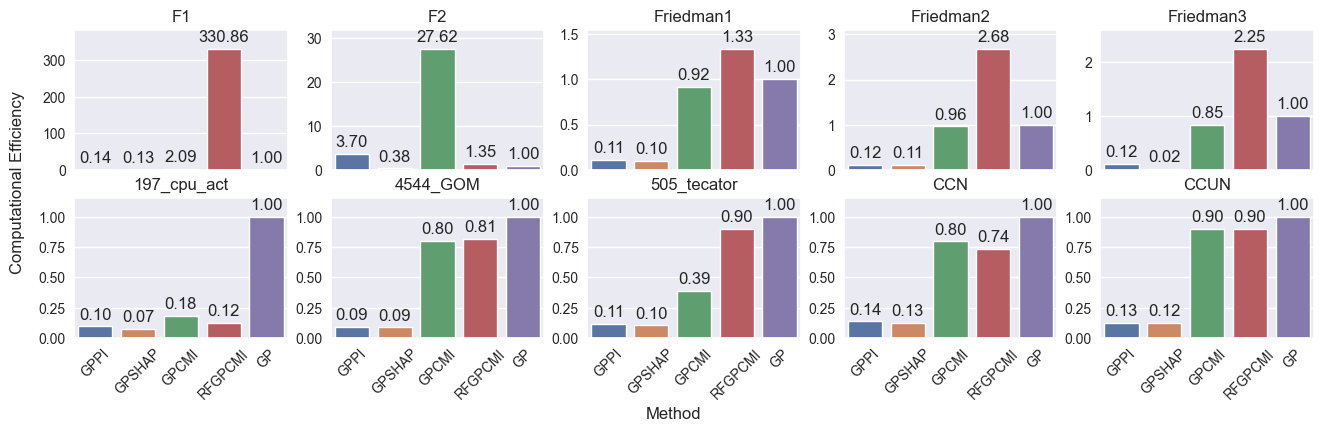

In [28]:
# Plotting the ratio of median test loss to median relative time for each dataset and method
fig, axes = plot_results(
    computational_efficiency_df, 
    nrows=2, 
    ncols=5, 
    subplot_kwargs={"sharex": True, "figsize": (16, 4)},
    group_level="dataset",
    value_level="metric", 
    value_key="test_losses",
    plotting_function=lambda data, ax: sns.barplot(data=data, ax=ax),
)

# Set X and Y label for the entire figure
fig.supxlabel("Method", x=0.5, y=-0.1, size=12)
fig.supylabel("Computational Efficiency", x=0.085, y=0.5, size=12)

# Add value labels on top of each bar and adjust y-axis limits for better visibility
for ax in axes:
    base_padding = 3
    margin_ratio = 0.1

    bottom, top = ax.get_ylim()
    y_padding = margin_ratio * (top - bottom)

    new_top = top + (y_padding if top else 0)
    new_bottom = bottom - (y_padding if bottom else 0)
    ax.set_ylim(new_bottom, new_top)

    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f', padding=base_padding)

    ax.set_xlabel("") # Hide the x-label
    ax.tick_params(axis='both', which='major', labelsize=10, pad=0)
    ax.tick_params(axis='x', which='major', labelrotation=45)

plt.show()

### Bonus

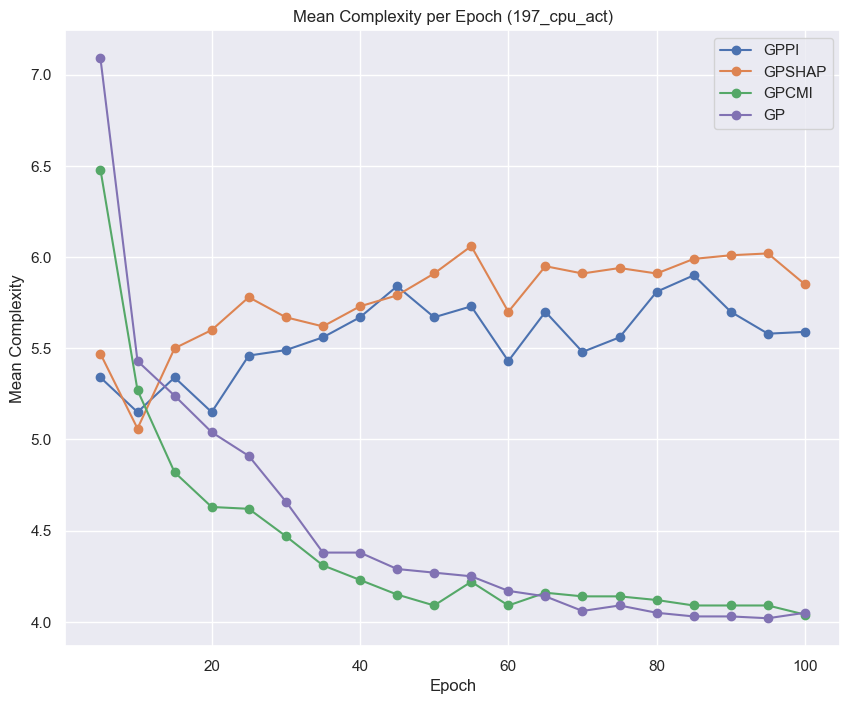

In [29]:
# Mean Complexity Analysis (197_cpu_act)

num_epochs = len(equations['197_cpu_act']['GPPI'][0])
methods_to_plot = [m for m in order['method'] if m != 'RFGPCMI']
method_colors = dict(zip(
    order['method'], 
    sns.color_palette(n_colors=len(order['method']))
))

# Calculate mean complexity for each method
mean_complexities = {}
for m in methods_to_plot:
    mean_complexities[m] = np.empty((num_epochs, num_runs))
    
    for r in range(num_runs):
        for i in range(num_epochs):
            mean_complexities[m][i, r] = equations['197_cpu_act'][m][r][i].complexity
    
    mean_complexities[m] = mean_complexities[m].mean(axis=1)

mean_complexities_df = pd.DataFrame(mean_complexities, index=results_df.index.get_level_values('epoch').unique())
mean_complexities_df = mean_complexities_df[methods_to_plot]

mean_complexities_df.plot(
    figsize=(10, 8), 
    title="Mean Complexity per Epoch (197_cpu_act)", 
    xlabel="Epoch", 
    ylabel="Mean Complexity", 
    marker='o',
    color=method_colors
)
plt.show()

In [30]:
# Print the best final expression for each method on the 197_cpu_act dataset 

dataset_name = '197_cpu_act'

# Print best final expression for each method
for m in order['method']:
    best_run_idx = results_df[dataset_name][m].test_losses.groupby(level='run').last().idxmin()
    
    # Different handling for RFGPCMI since it has multiple sub-expressions
    if m == "RFGPCMI":
        print(f'{m:<7} | {
            sum(
                equations[dataset_name][m][best_run_idx][i][-1].sympy_format
                for i in range(3)
            )
        }')

    else:
        print(f'{m:<7} | {equations[dataset_name][m][best_run_idx][-1].sympy_format}')

    print("-"*20)

GPPI    | freeswap/(0.010456718*freeswap + 7.3099637*vflt)
--------------------
GPSHAP  | (30.267262 - 0.013201188*vflt)*(atan(freeswap - vflt) + 1.5583527)
--------------------
GPCMI   | 2.8240192*freeswap**(1/4) - sqrt(pflt)
--------------------
RFGPCMI | -0.010074394*sread - sqrt(vflt) + 13.816394 + 1/(0.011490004 + 1/freeswap)
--------------------
GP      | 61.467552*atan(sqrt(freeswap)/vflt)
--------------------
